In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df.columns.tolist()

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'smoking_history',
 'bmi',
 'HbA1c_level',
 'blood_glucose_level',
 'diabetes']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [5]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [6]:
df["diabetes"].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [7]:
df = df.drop_duplicates().dropna()
print("Dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape: (96146, 9)
Remaining missing values: 0


In [8]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96146, 8)
y shape: (96146,)


In [9]:
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.head())

    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   gender_Male  gender_Other  smoking_history_current  smoking_history_ever  \
0            0             0                        0                     0   
1            0             0                        0                     0   
2            1             0                        0                     0   
3            0             0                        1                     0   
4            1             0                        1                     0   

   smoking_history_former  smoking_his

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling completed!")

Feature scaling completed!


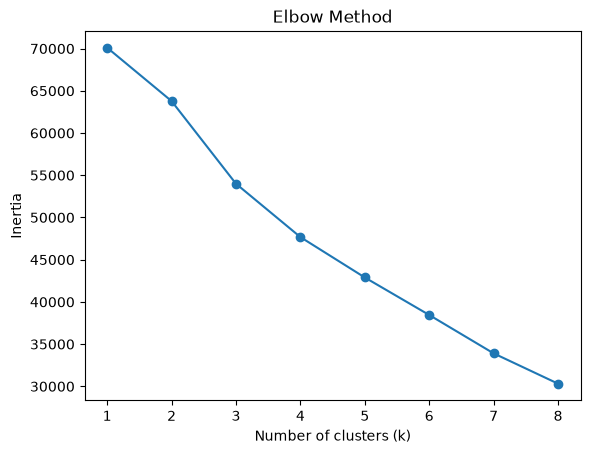

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# Use a reproducible sample for faster plotting on large datasets.
rs = np.random.RandomState(42)
idx = rs.choice(len(X_scaled), size=min(5000, len(X_scaled)), replace=False)
X_sample = X_scaled[idx]
inertias = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    inertias.append(km.inertia_)
plt.plot(range(1, 9), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [12]:
model = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = model.fit_predict(X_scaled)
print("K-Means clustering completed!")
print("Cluster counts:", pd.Series(clusters).value_counts().sort_index())

K-Means clustering completed!
Cluster counts: 0    74939
1    21207
Name: count, dtype: int64


In [13]:
from sklearn.metrics import silhouette_score, adjusted_rand_score
print("Inertia:", round(model.inertia_, 2))
print("Sample silhouette score:", round(silhouette_score(X_scaled[idx], model.predict(X_scaled[idx])), 3))
print("Adjusted Rand Index vs diabetes labels (reference only):", round(adjusted_rand_score(y, clusters), 3))
print("Clusters are NOT automatically diabetes predictions.")

Inertia: 1132260.87
Sample silhouette score: 0.263
Adjusted Rand Index vs diabetes labels (reference only): 0.132
Clusters are NOT automatically diabetes predictions.


In [14]:
print(pd.crosstab(pd.Series(clusters, name="Cluster"), y.reset_index(drop=True), normalize="index"))

diabetes         0         1
Cluster                     
0         0.944341  0.055659
1         0.796718  0.203282


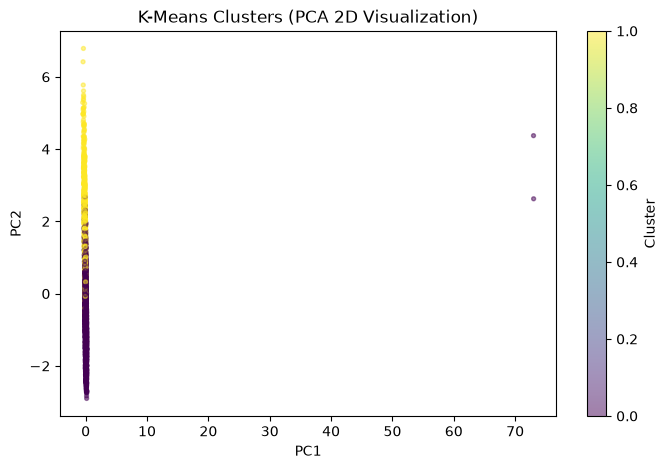

In [15]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled[idx])
plt.figure(figsize=(8, 5))
plt.scatter(coords[:, 0], coords[:, 1], c=clusters[idx], cmap="viridis", s=8, alpha=0.5)
plt.title("K-Means Clusters (PCA 2D Visualization)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.show()

In [16]:
new_person = pd.DataFrame([{
    "gender": "Female", "age": 45, "hypertension": 0,
    "heart_disease": 0, "smoking_history": "never",
    "bmi": 27.5, "HbA1c_level": 5.8, "blood_glucose_level": 140
}])
new_person = pd.get_dummies(pd.concat([df.drop(columns=["diabetes"]), new_person], ignore_index=True), drop_first=True, dtype=int).tail(1)
new_person = new_person.reindex(columns=X.columns, fill_value=0)
print("Assigned cluster:", model.predict(scaler.transform(new_person))[0])
print("Cluster labels are groups, not disease diagnoses.")

Assigned cluster: 0
Cluster labels are groups, not disease diagnoses.
